## Current research direction — HRI adaptation

Reusable preparation: review and adapt these steps for endemic-bird HRI assessment. Any legacy forest-loss target analysis in this notebook is exploratory, not an HRI definition.

The original code and saved outputs are retained. No cells were executed during restoration. Use `docs/methodology/hri_workflow.md` for the current direction and `notebooks/hri/` for the simple lecturer-facing versions. Do not describe existing forest-loss outputs as habitat-risk classes.

# 04 — Sri Lanka spatial units and species context

Study area: **all Sri Lanka**, confirmed by the researcher. This notebook constructs a **provisional 5 km grid**, links recorded species to cells, and prepares a source-backed species-traits template. The grid resolution is a computational starting point, not a validated ecological scale; compare alternatives before freezing the analysis.

Habitat threat, species vulnerability and conservation priority are separate concepts. This notebook does **not** calculate HRI, predict future risk, assign vulnerability weights or invent IUCN categories. Existing environmental-source verification is deferred.

Boundary: geoBoundaries gbOpen LKA ADM0. The original downloaded geometry and metadata are saved under `data/raw/boundaries/`. This is a working research boundary, not a claim of official approval. See the [provider API documentation](https://www.geoboundaries.org/api.html) and saved source/licence metadata. Points outside this boundary are retained for review rather than snapped or silently discarded.

In [7]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "configs/study.json").is_file()
             and (p / "data/interim/location_reference.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open the component4 project or notebooks directory.")
cfg = json.loads((ROOT / "configs/study.json").read_text())
OUT = ROOT / "data/interim/spatial"
FIGURES = ROOT / "reports/figures"
OUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
size = int(cfg["grid_size_m"])
assert size > 0
run_id = f"lka_laea_{size}m"
print(json.dumps(cfg, indent=2))

{
  "study_area": "All Sri Lanka",
  "boundary_file": "data/raw/boundaries/LKA_ADM0.geojson",
  "grid_size_m": 5000,
  "grid_status": "provisional exploration; assess ecological scale before modelling",
  "projected_crs": "+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84 +units=m +no_defs",
  "grid_origin_m": [
    0,
    0
  ],
  "species_scope": "Endemic birds; resolve taxonomy and eligibility before filtering retained records",
  "source_verification": "See source registry: forest/weather/terrain sources acquired; observation/trait limitations remain",
  "priority_method": "Not selected; no vulnerability weights or priority scores assigned",
  "research_direction": "Endemic-bird habitat-risk assessment using a justified HRI"
}


## 1. Boundary and coordinate checks

Input latitude/longitude are provisionally interpreted as WGS84, consistent with their ranges; confirm this against the observation export. Use a local Lambert azimuthal equal-area projection centered on Sri Lanka for grid construction and area calculation. Grid distances are projected distances. Do not calculate square kilometres directly from latitude/longitude.

The grid origin and CRS are fixed in the configuration. Cell IDs include resolution and projected grid indices; changing CRS/origin requires a new grid version. Boundary slivers and offshore points need review.

In [8]:
boundary_path = ROOT / cfg["boundary_file"]
metadata = json.loads(boundary_path.with_name("LKA_ADM0_metadata.json").read_text())
assert hashlib.sha256(boundary_path.read_bytes()).hexdigest() == metadata["download_sha256"]
boundary = gpd.read_file(boundary_path)
assert boundary.crs is not None
assert boundary.geometry.is_valid.all() and not boundary.geometry.is_empty.any()
boundary = boundary.to_crs(cfg["projected_crs"])
land = boundary.geometry.union_all()
locations = pd.read_csv(ROOT / "data/interim/location_reference.csv")
assert locations["location_id"].is_unique
assert locations["latitude"].between(-90, 90).all()
assert locations["longitude"].between(-180, 180).all()
points = gpd.GeoDataFrame(locations, geometry=gpd.points_from_xy(
    locations.longitude, locations.latitude), crs="EPSG:4326").to_crs(boundary.crs)
points["inside_boundary"] = points.geometry.covered_by(land)
print("Locations:", len(points))
print("Inside working boundary:", int(points.inside_boundary.sum()))
print("Outside working boundary (review):", int((~points.inside_boundary).sum()))
print("Source:", metadata.get("boundarySource", metadata.get("boundarySource-1", "See metadata")))
display(points.loc[~points.inside_boundary, ["location_id", "latitude", "longitude"]].head(20))

Locations: 7245
Inside working boundary: 7228
Outside working boundary (review): 17
Source: OpenStreetMap, Wambacher


,location_id,latitude,longitude
21,LOC_000022,5.943758,80.621753
264,LOC_000265,6.042605,80.860462
670,LOC_000671,6.233395,81.372739
2154,LOC_002155,6.495442,79.971460
2377,LOC_002378,6.645584,79.932111
4890,LOC_004891,7.149098,79.844685
4940,LOC_004941,7.170308,79.864185
5063,LOC_005064,7.213399,79.834117
6415,LOC_006416,7.980018,79.824514
7123,LOC_007124,8.902670,79.932227


### Review locations outside the working boundary

These points may reflect coastal boundary differences, offshore records or coordinate problems. Inspect the original observations and map before deciding. This export does not classify them as errors, delete records or change coordinates. Rerunning refreshes the coordinate list; keep manual review decisions in a separate file.

In [9]:
# Export flagged locations for inspection; do not delete or move them.
outside_locations = points.loc[
    ~points["inside_boundary"],
    ["location_id", "latitude", "longitude"]
].copy()

review_path = OUT / "outside_boundary_locations_review.csv"
outside_locations.to_csv(review_path, index=False)
display(outside_locations)
print("Locations requiring review:", len(outside_locations))
print("Saved to:", review_path)


,location_id,latitude,longitude
21,LOC_000022,5.943758,80.621753
264,LOC_000265,6.042605,80.860462
670,LOC_000671,6.233395,81.372739
2154,LOC_002155,6.495442,79.971460
2377,LOC_002378,6.645584,79.932111
4890,LOC_004891,7.149098,79.844685
4940,LOC_004941,7.170308,79.864185
5063,LOC_005064,7.213399,79.834117
6415,LOC_006416,7.980018,79.824514
7123,LOC_007124,8.902670,79.932227


Locations requiring review: 17
Saved to: /Users/keerthikeerthi/Desktop/component4/data/interim/spatial/outside_boundary_locations_review.csv


## 2. Build cells across the whole country

Cells are clipped to the boundary; coastal cells have less land area. No sampling record is required for a cell to exist. Keep valid land area for later area-weighted summaries. Absence of a recorded species does not establish ecological absence or low risk.

Point assignment uses half-open projected grid intervals, so a point on an internal grid edge receives one deterministic cell ID. This avoids duplicated assignments from polygon intersections.

In [10]:
ox, oy = cfg["grid_origin_m"]
xmin, ymin, xmax, ymax = land.bounds
records = []
for ix in range(int(np.floor((xmin-ox)/size)), int(np.floor((xmax-ox)/size))+1):
    for iy in range(int(np.floor((ymin-oy)/size)), int(np.floor((ymax-oy)/size))+1):
        square = box(ox+ix*size, oy+iy*size, ox+(ix+1)*size, oy+(iy+1)*size)
        if not square.intersects(land):
            continue
        clipped = square.intersection(land)
        if clipped.area > 0:
            records.append({"cell_id": f"{run_id}_{ix}_{iy}", "grid_x": ix, "grid_y": iy,
                            "land_area_km2": clipped.area/1e6, "geometry": clipped})
grid = gpd.GeoDataFrame(records, crs=boundary.crs)
assert grid.cell_id.is_unique and grid.geometry.is_valid.all()
assert np.isclose(grid.land_area_km2.sum(), land.area/1e6, rtol=1e-7)
points["grid_x"] = np.floor((points.geometry.x-ox)/size).astype(int)
points["grid_y"] = np.floor((points.geometry.y-oy)/size).astype(int)
points["candidate_cell_id"] = [f"{run_id}_{x}_{y}" for x,y in zip(points.grid_x, points.grid_y)]
points["cell_id"] = points.candidate_cell_id.where(points.inside_boundary)
assert points.loc[points.inside_boundary, "cell_id"].isin(grid.cell_id).all()
print("Country grid cells:", len(grid))
print("Total clipped land area (km²):", round(grid.land_area_km2.sum(), 2))

Country grid cells: 2869
Total clipped land area (km²): 66068.91


## 3. Species-traits evidence template

The template lists the recorded scientific names without asserting that taxonomy or endemic status has been verified. Fill each trait with its own evidence source and assessment/review date. Use global versus national IUCN status explicitly. Unknown traits remain blank, never zero vulnerability. If all included species are endemic, endemic status will not distinguish their relative priority.

The template is only initialized if absent, so reruns preserve manual edits. When new species enter the source dataset, the consistency check asks you to reconcile the registry rather than overwriting it. Forest-interior specialization and elevation association need species-specific evidence. Do not infer either from a single observation.

**Source review update (1 October 2026):** The existing registry now holds cited endemism evidence and 2025 BirdLife global-category matches, with assessment names separate from original observation names. See `data/metadata/species_traits_README.md`. The Sri Lanka Frogmouth is non-endemic; Sri Lanka Thrush has an unresolved BirdLife/Clements taxon mismatch. Keep unknown categories and traits missing. This notebook does not apply an endemic-only filter or priority weights.

In [11]:
species_locations = pd.read_csv(ROOT / "data/interim/species_location_review.csv")
names = (species_locations.groupby("scientific_name")["common_name"]
         .agg(lambda x: " | ".join(sorted(set(x.dropna())))).reset_index())
traits_path = ROOT / "data/metadata/species_traits.csv"
if not traits_path.exists():
    traits = names.copy()
    for field in ["accepted_scientific_name", "taxonomy_source", "endemic_status", "endemic_source",
                  "iucn_category", "iucn_assessment_scope", "iucn_assessment_date", "iucn_source",
                  "forest_dependence", "forest_dependence_source", "elevation_min_m", "elevation_max_m",
                  "elevation_source", "inclusion_decision", "reviewed_by", "reviewed_on", "notes"]:
        traits[field] = ""
    traits["verification_status"] = "unverified"
    traits.to_csv(traits_path, index=False)
traits = pd.read_csv(traits_path, keep_default_na=False)
assert traits.scientific_name.is_unique
assert set(names.scientific_name) <= set(traits.scientific_name), "Reconcile new species in traits registry."
print("Recorded scientific names:", len(names))
display(traits[["scientific_name", "common_name", "endemic_status", "iucn_category", "verification_status"]])

Recorded scientific names: 25


,scientific_name,common_name,endemic_status,iucn_category,verification_status
0,Argya cinereifrons,Ashy-headed Laughingthrush,yes,VU,partially_verified
1,Batrachostomus moniliger,Sri Lanka Frogmouth,no,LC,partially_verified
2,Centropus chlororhynchos,Green-billed Coucal,yes,VU,partially_verified
3,Chrysocolaptes stricklandi,Crimson-backed Flameback,yes,LC,partially_verified
4,Columba torringtoniae,Sri Lanka Wood-Pigeon,yes,VU,partially_verified
5,Dicrurus lophorinus,Sri Lanka Drongo,yes,LC,partially_verified
6,Dinopium psarodes,Red-backed Flameback,yes,LC,partially_verified
7,Galloperdix bicalcarata,Sri Lanka Spurfowl,yes,LC,partially_verified
8,Gallus lafayettii,Sri Lanka Junglefowl,yes,LC,partially_verified
9,Geokichla spiloptera,Spot-winged Thrush,yes,NT,partially_verified


## 4. Map recorded species into cells

Summaries below pool the current observation period and are descriptive only. `recorded_species_count` measures distinct recorded names in this dataset, not true richness, corrected diversity or vulnerability. A full-period species table must not be used as information available at an earlier forecast cutoff. Historical modelling requires time-filtered occurrence context and date-appropriate traits.

Record counts retain existing duplication and effort biases. Counts are exported for review, not used as conservation weights. Outside-boundary locations remain in the location audit but do not contribute to within-country summaries.

In [12]:
assert species_locations.location_id.isin(points.location_id).all()
linked = species_locations.merge(points[["location_id", "cell_id", "inside_boundary"]],
                                 on="location_id", validate="many_to_one")
inside = linked.loc[linked.inside_boundary].copy()
cell_species = (inside.groupby(["cell_id", "scientific_name"])
                .agg(recorded_locations=("location_id", "nunique"),
                     first_observed=("first_observed", "min"),
                     last_observed=("last_observed", "max"),
                     raw_record_count=("record_count", "sum"))
                .reset_index())
assert not cell_species.duplicated(["cell_id", "scientific_name"]).any()
cell_species = cell_species.merge(traits, on="scientific_name", validate="many_to_one")
counts = cell_species.groupby("cell_id").scientific_name.nunique()
location_counts = points.loc[points.inside_boundary].groupby("cell_id").size()
grid["recorded_species_count"] = grid.cell_id.map(counts).fillna(0).astype(int)
grid["recorded_location_count"] = grid.cell_id.map(location_counts).fillna(0).astype(int)
grid["occurrence_evidence"] = np.where(grid.recorded_species_count.gt(0), "recorded_presence", "insufficient_evidence")
grid["vulnerability_status"] = "not_scored"
grid["priority_status"] = "not_scored"
print("Cells with recorded species:", int(grid.recorded_species_count.gt(0).sum()))
print("Cells with insufficient occurrence evidence:", int(grid.recorded_species_count.eq(0).sum()))
display(cell_species.head())

Cells with recorded species: 1112
Cells with insufficient occurrence evidence: 1757


,cell_id,scientific_name,recorded_locations,first_observed,last_observed,raw_record_count,common_name,accepted_scientific_name,taxonomy_source,endemic_status,...,taxonomy_match_status,iucn_snapshot_year,iucn_assessment_year,iucn_assessment_date_precision,iucn_assessment_date_source,birdlife_sis_id,birdlife_checklist_code,birdlife_checklist_row,trait_evidence_status,source_accessed_on
0,lka_laea_5000m_-10_-11,Dinopium psarodes,1,2023-04-30,2023-04-30,1,Red-backed Flameback,Dinopium psarodes,https://avibase.bsc-eoc.org/checklist.jsp?lang...,yes,...,exact_name,2025,,unknown,,61517218,LC,9573,Endemism and observation-name taxonomy support...,2026-10-01
1,lka_laea_5000m_-10_-12,Dinopium psarodes,2,2017-10-01,2019-09-23,3,Red-backed Flameback,Dinopium psarodes,https://avibase.bsc-eoc.org/checklist.jsp?lang...,yes,...,exact_name,2025,,unknown,,61517218,LC,9573,Endemism and observation-name taxonomy support...,2026-10-01
2,lka_laea_5000m_-10_-12,Gallus lafayettii,2,2018-01-19,2020-04-15,2,Sri Lanka Junglefowl,Gallus lafayettii,https://avibase.bsc-eoc.org/checklist.jsp?lang...,yes,...,exact_name,2025,,unknown,,22679209,LC,906,Endemism and observation-name taxonomy support...,2026-10-01
3,lka_laea_5000m_-10_-12,Loriculus beryllinus,1,2018-01-19,2018-01-19,1,Sri Lanka Hanging-Parrot,Loriculus beryllinus,https://avibase.bsc-eoc.org/checklist.jsp?lang...,yes,...,exact_name,2025,,unknown,,22685371,LC,11129,Endemism and observation-name taxonomy support...,2026-10-01
4,lka_laea_5000m_-10_-12,Ocyceros gingalensis,3,2016-08-07,2023-05-18,5,Sri Lanka Gray Hornbill,Ocyceros gingalensis,https://avibase.bsc-eoc.org/checklist.jsp?lang...,yes,...,exact_name,2025,,unknown,,22682425,LC,8215,Endemism and observation-name taxonomy support...,2026-10-01


## 5. Exploratory maps and saved outputs

The map shows recorded coverage, not habitat risk. Grey cells lack occurrence evidence in this dataset. Exported GeoJSON uses WGS84 for display; area attributes were calculated in the configured equal-area CRS. Always retain `configs/study.json` and source metadata with exports.

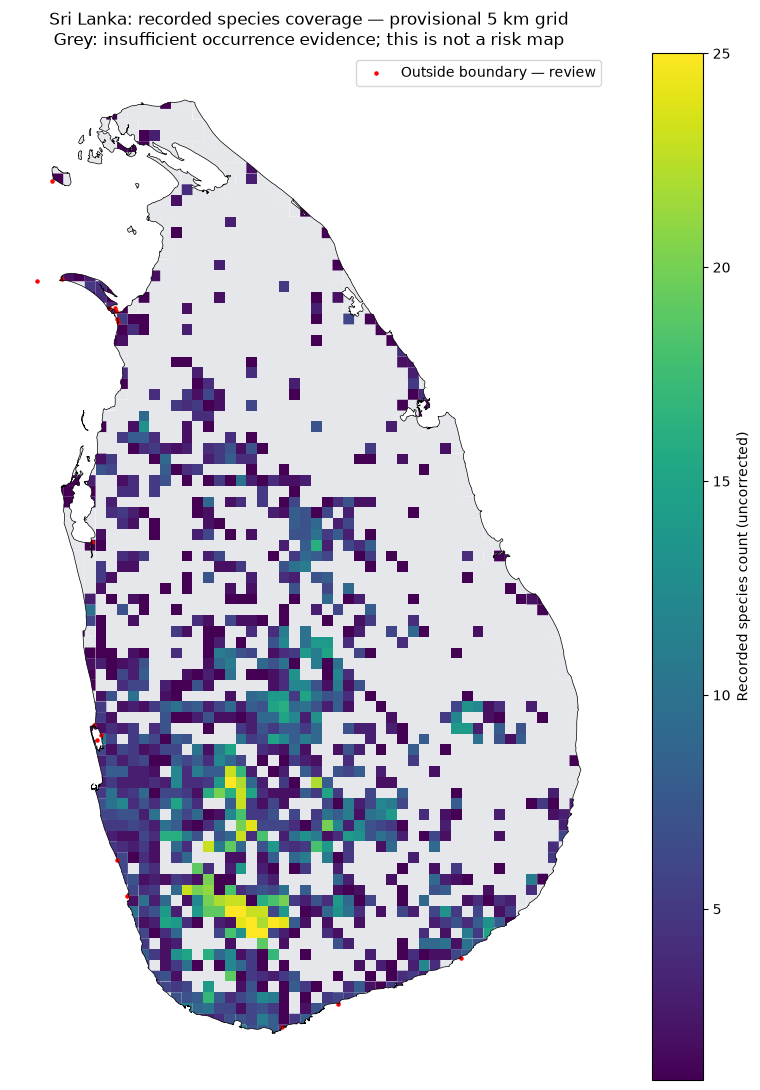

Outputs: /Users/keerthikeerthi/Desktop/component4/data/interim/spatial
Traits registry (manual edits preserved): /Users/keerthikeerthi/Desktop/component4/data/metadata/species_traits.csv


In [13]:
fig, ax = plt.subplots(figsize=(9, 11))
grid.plot(ax=ax, color="#e5e7eb", edgecolor="none")
observed_grid = grid.loc[grid.recorded_species_count.gt(0)]
if not observed_grid.empty:
    observed_grid.plot(ax=ax, column="recorded_species_count", cmap="viridis", legend=True,
                       legend_kwds={"label": "Recorded species count (uncorrected)"})
boundary.boundary.plot(ax=ax, color="black", linewidth=0.5)
outside = points.loc[~points.inside_boundary]
if not outside.empty:
    outside.plot(ax=ax, color="red", markersize=5, label="Outside boundary — review")
    ax.legend(loc="upper right")
ax.set_title(f"Sri Lanka: recorded species coverage — provisional {size/1000:g} km grid\nGrey: insufficient occurrence evidence; this is not a risk map")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIGURES / f"{run_id}_species_coverage.png", dpi=180)
plt.show()
plt.close(fig)

grid.to_crs("EPSG:4326").to_file(OUT / f"{run_id}_grid.geojson", driver="GeoJSON")
points.drop(columns="geometry").to_csv(OUT / f"{run_id}_location_assignments.csv", index=False)
cell_species.to_csv(OUT / f"{run_id}_cell_species.csv", index=False)
grid.drop(columns="geometry").to_csv(OUT / f"{run_id}_cell_summary.csv", index=False)
summary = {"grid_id": run_id, "study_area": cfg["study_area"], "grid_cells": len(grid),
           "locations": len(points), "outside_boundary_locations": int((~points.inside_boundary).sum()),
           "cells_with_records": int(grid.recorded_species_count.gt(0).sum()),
           "recorded_scientific_names": len(names), "priority_scores_calculated": False,
           "boundary_sha256": metadata["download_sha256"], "config": cfg}
(ROOT / "reports/audits/spatial_grid_summary.json").write_text(json.dumps(summary, indent=2)+"\n")
print("Outputs:", OUT)
print("Traits registry (manual edits preserved):", traits_path)

## 6. Next research decisions

1. Review the map and outside-boundary records, especially coastal sites; do not automatically snap points inland.
2. Compare provisional cell sizes and justify a final scale. Spatial validation blocks are a separate, usually larger-scale choice.
3. Verify the species traits and decide endemic-only eligibility. Retain unknown statuses explicitly.
4. Build dated environmental features and future labels; the current notebook has no environmental-risk feature matrix.
5. Specify how habitat threat and species vulnerability produce conservation priority, with justified aggregation and weights. Compare an unweighted reference, vulnerability-aware alternatives and sensitivity results. Avoid double-counting related traits such as endemism and threat status.
6. Distinguish absence of evidence from low priority. Do not rank cells yet: both validated threat estimates and verified trait inputs are missing.

Species vulnerability modifies conservation priority; it does not by itself change the measured environmental threat. SHAP can later explain a fitted prediction, while the species-priority rules need their own transparent explanation and ecological review.

# HRI preparation — combine the existing evidence

This section is self-contained after Notebook 02's **HRI preparation** section has been run. It reuses the saved national grid; no redownload or hidden pipeline is needed.

Outputs are (1) cell-year environmental evidence and (2) cell-year-species occurrence evidence, linked by cell/year. They are preprocessing candidates, not a finalized HRI dataset. Keep every country cell in the environmental table; no observation is not bird absence. Species-trait snapshots stay in the species table, not historical predictors. No HRI scores or classes are created.

Duplicate observations remain flagged: reported counts describe records, not independent checklists or abundance. Rows with invalid dates or unmapped coordinates cannot join and are saved for review. Other flags remain in the species summaries.

In [14]:
from pathlib import Path
import json
import pandas as pd
ROOT = Path.cwd()
while not (ROOT / "configs/study.json").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run within component4")
    ROOT = ROOT.parent
cfg = json.loads((ROOT / "configs/study.json").read_text())
grid_id = f"lka_laea_{cfg['grid_size_m']}m"
SPATIAL = ROOT / "data/interim/spatial"
OUT = ROOT / "data/interim/hri"
OUT.mkdir(parents=True, exist_ok=True)
birds = pd.read_csv(OUT / "endemic_bird_candidates.csv")
grid = pd.read_csv(SPATIAL / f"{grid_id}_cell_summary.csv")
locations = pd.read_csv(SPATIAL / f"{grid_id}_location_assignments.csv")
weather = pd.read_csv(SPATIAL / f"{grid_id}_weather_features.csv")
terrain = pd.read_csv(SPATIAL / f"{grid_id}_terrain_features.csv")
forest = pd.read_csv(SPATIAL / f"{grid_id}_forest_evidence.csv")
histogram = pd.read_csv(SPATIAL / f"{grid_id}_canopy_loss_histogram.csv")
print("Grid cells:", len(grid), "Endemic candidate rows:", len(birds))

Grid cells: 2869 Endemic candidate rows: 101581


## A. Check unique join keys before combining
Only the structural grid fields are used. Pooled species counts and full-period loss outcomes are excluded from the environmental predictors.

In [15]:
for name, table in [("grid", grid), ("terrain", terrain), ("forest", forest)]:
    assert table["cell_id"].is_unique, f"Duplicate key in {name}"
assert not locations.duplicated(["latitude", "longitude"]).any()
assert not weather.duplicated(["cell_id", "reference_year"]).any()
assert not histogram.duplicated(["cell_id", "canopy_percent", "loss_year_code"]).any()
assert histogram["loss_year_code"].between(0, 24).all()
assert histogram["cell_id"].isin(grid["cell_id"]).all()
for table in [terrain, forest]:
    assert set(table["cell_id"]) == set(grid["cell_id"])
assert weather["cell_id"].isin(grid["cell_id"]).all()
print("Join keys checked.")

Join keys checked.


## B. Build one environmental row per cell and year
Use the saved weather years 2010–2023. Missing values stay missing and coverage flags remain visible. Terrain is static and weather describes a whole calendar year, not weather on a bird observation date.

In [16]:
years = pd.DataFrame({"reference_year": range(2010, 2024)})
environment = grid[["cell_id", "grid_x", "grid_y", "land_area_km2"]].merge(years, how="cross")
environment = environment.merge(weather, on=["cell_id", "reference_year"], how="left", validate="one_to_one")
environment = environment.merge(terrain, on="cell_id", how="left", validate="many_to_one")
forest = forest.rename(columns={"status": "forest_evidence_status"})
environment = environment.merge(forest, on="cell_id", how="left", validate="many_to_one")
assert len(environment) == len(grid) * len(years)
environment.head()

,cell_id,grid_x,grid_y,land_area_km2,reference_year,annual_mean_temperature_c,annual_mean_temperature_c_coverage,annual_precipitation_mm,annual_precipitation_mm_coverage,weather_status,...,mean_slope_degrees,terrain_status,sampled_pixels,sampled_area_m2,no_data_area_m2,mapped_land_area_m2,persistent_water_area_m2,observed_area_fraction_of_sampled_footprint,mean_canopy_percent_on_mapped_land,forest_evidence_status
0,lka_laea_5000m_-24_35,-24,35,0.01672,2010,NaN,0.0,NaN,0.0,insufficient_source_coverage,...,NaN,no_pixel_centres,26,19733.757991,0.0,19733.757991,0.0,1.0,0.0,evidence_available
1,lka_laea_5000m_-24_35,-24,35,0.01672,2011,NaN,0.0,NaN,0.0,insufficient_source_coverage,...,NaN,no_pixel_centres,26,19733.757991,0.0,19733.757991,0.0,1.0,0.0,evidence_available
2,lka_laea_5000m_-24_35,-24,35,0.01672,2012,NaN,0.0,NaN,0.0,insufficient_source_coverage,...,NaN,no_pixel_centres,26,19733.757991,0.0,19733.757991,0.0,1.0,0.0,evidence_available
3,lka_laea_5000m_-24_35,-24,35,0.01672,2013,NaN,0.0,NaN,0.0,insufficient_source_coverage,...,NaN,no_pixel_centres,26,19733.757991,0.0,19733.757991,0.0,1.0,0.0,evidence_available
4,lka_laea_5000m_-24_35,-24,35,0.01672,2014,NaN,0.0,NaN,0.0,insufficient_source_coverage,...,NaN,no_pixel_centres,26,19733.757991,0.0,19733.757991,0.0,1.0,0.0,evidence_available


## C. Summarise dated forest disturbance, without choosing an HRI weight

This is mapped loss over **all datamask land**; no forest-canopy threshold is silently adopted. Loss area for year t and the last three years is evidence for later indicator design. The denominator for the fraction is mapped land area, not remaining forest. Missing/no-land denominators stay undefined. Code 0 is no mapped loss; future loss codes are never included in the annual or cumulative totals. The sparse histogram is complete for mapped land; only absent categories within that histogram can be treated as zero.

In [17]:
loss_by_code = histogram.pivot_table(
    index="cell_id", columns="loss_year_code", values="mapped_land_area_m2",
    aggfunc="sum", fill_value=0
).reindex(index=grid["cell_id"], columns=range(25), fill_value=0)
forest_years = []
for year in range(2010, 2024):
    code = year - 2000
    table = pd.DataFrame({
        "cell_id": loss_by_code.index,
        "reference_year": year,
        "mapped_loss_area_in_year_m2": loss_by_code[code].to_numpy(),
        "mapped_loss_area_last_3_years_m2": loss_by_code.loc[:, code-2:code].sum(axis=1).to_numpy(),
        "mapped_loss_area_through_year_m2": loss_by_code.loc[:, 1:code].sum(axis=1).to_numpy()
    })
    forest_years.append(table)
forest_years = pd.concat(forest_years, ignore_index=True)
environment = environment.merge(forest_years, on=["cell_id", "reference_year"], validate="one_to_one")
land = environment["mapped_land_area_m2"].where(environment["mapped_land_area_m2"].gt(0))
environment["mapped_loss_fraction_of_land_in_year"] = environment["mapped_loss_area_in_year_m2"] / land
loss_columns = ["mapped_loss_area_in_year_m2", "mapped_loss_area_last_3_years_m2", "mapped_loss_area_through_year_m2"]
environment.loc[land.isna(), loss_columns] = float("nan")
assert environment["mapped_loss_fraction_of_land_in_year"].dropna().between(0, 1).all()

## D. Map endemic bird records to cells
Join exact stored coordinates. Do not snap outside-boundary points into a neighbouring cell. Keep unmatched or undated rows for review.

In [18]:
linked = birds.merge(
    locations[["latitude", "longitude", "cell_id", "inside_boundary"]],
    on=["latitude", "longitude"], how="left", validate="many_to_one"
)
assert len(linked) == len(birds)
linked["reference_year"] = pd.to_datetime(linked["observation_date_parsed"], errors="coerce").dt.year.astype("Int64")
usable = linked["cell_id"].notna() & linked["reference_year"].between(2010, 2023).fillna(False)
map_review = linked.loc[~usable].copy()
mapped = linked.loc[usable].copy()
print("Mapped rows:", len(mapped), "Rows needing map/date review:", len(map_review))

Mapped rows: 101535 Rows needing map/date review: 46


## E. Summarise dated species evidence, keeping review counts
No count sum is interpreted as abundance. Current traits are attached once per species and explicitly retain source dates and verification status. Only records from the corresponding calendar year are counted.

In [19]:
species_year = mapped.groupby(["cell_id", "reference_year", "scientific_name"]).agg(
    observation_record_count=("scientific_name", "size"),
    possible_duplicate_records=("possible_duplicate", "sum"),
    record_review_count=("needs_review", "sum"),
    presence_only_records=("presence_only", "sum"),
    first_observed=("observation_date_parsed", "min"),
    last_observed=("observation_date_parsed", "max")
).reset_index()
traits = pd.read_csv(ROOT / "data/metadata/species_traits.csv")
traits["scientific_name"] = traits["scientific_name"].str.strip()
assert traits["scientific_name"].is_unique
species_year = species_year.merge(traits, on="scientific_name", how="left", validate="many_to_one")
assert not species_year.duplicated(["cell_id", "reference_year", "scientific_name"]).any()
occurrence = species_year.groupby(["cell_id", "reference_year"]).agg(
    recorded_endemic_species=("scientific_name", "nunique"),
    endemic_observation_records=("observation_record_count", "sum")
).reset_index()
environment = environment.merge(occurrence, on=["cell_id", "reference_year"], how="left", validate="one_to_one")
environment["endemic_occurrence_evidence"] = environment["recorded_endemic_species"].notna()
print("Missing occurrence summaries mean no retained evidence, not biological absence.")

Missing occurrence summaries mean no retained evidence, not biological absence.


## F. Retain environmental coverage flags and save preparation tables
The 95% thresholds below are existing working quality screens, not final ecological decisions. Save all rows and flag quality, rather than silently dropping less-observed cells. Species counts are descriptive context, not approved historical predictors. No HRI target exists yet.

In [20]:
environment["environment_coverage_pass"] = (
    environment["weather_status"].eq("coverage_pass")
    & environment["terrain_status"].eq("coverage_pass")
    & environment["observed_area_fraction_of_sampled_footprint"].ge(0.95)
    & environment["mapped_land_area_m2"].gt(0)
)
assert not environment.duplicated(["cell_id", "reference_year"]).any()
assert len(environment) == len(grid) * 14
assert species_year["cell_id"].isin(environment["cell_id"]).all()
environment.to_csv(OUT / "hri_cell_year_preparation.csv", index=False)
species_year.to_csv(OUT / "hri_cell_year_species_evidence.csv", index=False)
map_review.to_csv(OUT / "endemic_mapping_review.csv", index=False)
print("Environmental rows:", len(environment))
print("Species evidence rows:", len(species_year))
print("Coverage flags:", environment["environment_coverage_pass"].value_counts().to_dict())
print("Saved HRI preparation tables, not finalized risk scores or ML labels.")

Environmental rows: 40166
Species evidence rows: 16151
Coverage flags: {True: 34118, False: 6048}
Saved HRI preparation tables, not finalized risk scores or ML labels.


## Next research step

Review cleaning/exclusion decisions and source limitations, then specify the HRI indicators, transformations, weights, classes and validation. Fragmentation and human-pressure data are still missing from this integration. Weather/terrain do not automatically define risk. If forecasting is selected later, explicitly separate reference-period inputs and future labels. Do not train an ecological-risk model on a self-generated formula and interpret formula reconstruction as independent ecological validation.